# Ejemplo 1

In [1]:
# ejecutar si no se tienen las librerias requeridas:
!pip install tensorflow
!pip install scikit-learn
!pip install matplotlib
!pip install pydot
!pip install graphviz
# isntalar la aplicacion graphviz: https://graphviz.gitlab.io/download/

In [2]:
# importamos librerias
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import numpy as np
import sklearn
import sklearn.datasets
import sklearn.linear_model
import matplotlib.pyplot as plt
%matplotlib inline

I0000 00:00:1791704129.726150   14971 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791704129.766820   14971 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791704130.986579   14971 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [3]:
def plot_decision_boundary(model, X, y):
    # Set min and max values and give it some padding
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:,1].min() - 1, X[:,1].max() + 1
    h = 0.05
    # Generate a grid of points with distance h between them
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    # Predict the function value for the whole grid
    Z = model(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    # Plot the contour and training examples
    plt.contourf(xx, yy, Z, cmap=plt.cm.Spectral)
    plt.ylabel('x2')
    plt.xlabel('x1')
    plt.scatter(X[:,0], X[:,1], c=y.ravel(), cmap=plt.cm.Spectral)

def plot_history(history: tf.keras.callbacks.History) -> None:
    """Plot training and validation loss/accuracy curves."""
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].plot(history.history['loss'], label='train')
    axes[0].plot(history.history['val_loss'], label='val')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].legend()

    axes[1].plot(history.history['accuracy'], label='train')
    axes[1].plot(history.history['val_accuracy'], label='val')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy')
    axes[1].legend()
    plt.tight_layout()
    
def load_planar_dataset(m, sigma=0.2):
    N = int(m/2) # number of points per class
    D = 2 # dimensionality
    X = np.zeros((m,D)) # data matrix where each row is a single example
    Y = np.zeros((m,1), dtype='uint8') # labels vector (0 for red, 1 for blue)
    a = 4 # maximum ray of the flower

    for j in range(2):
        ix = range(N*j,N*(j+1))
        t = np.linspace(j*3.12,(j+1)*3.12,N) + np.random.randn(N)*sigma # theta
        r = a*np.sin(4*t) + np.random.randn(N)*sigma # radius
        X[ix] = np.c_[r*np.sin(t), r*np.cos(t)]
        Y[ix] = j
        
    ## premuting ouput
    p = np.random.permutation(m)
    X = X[p,:]
    Y = Y[p,:]

    return X, Y.ravel()

def draw_neural_net(left, right, bottom, top, layer_sizes):
    '''
    From https://gist.github.com/craffel/2d727968c3aaebd10359#file-draw_neural_net-py
    Draw a neural network cartoon using matplotilb.
    
    :usage:
        >>> fig = plt.figure(figsize=(12, 12))
        >>> draw_neural_net(fig.gca(), .1, .9, .1, .9, [4, 7, 2])
    
    :parameters:
        - ax : matplotlib.axes.AxesSubplot
            The axes on which to plot the cartoon (get e.g. by plt.gca())
        - left : float
            The center of the leftmost node(s) will be placed here
        - right : float
            The center of the rightmost node(s) will be placed here
        - bottom : float
            The center of the bottommost node(s) will be placed here
        - top : float
            The center of the topmost node(s) will be placed here
        - layer_sizes : list of int
            List of layer sizes, including input and output dimensionality
    '''
    fig = plt.figure(figsize=(3, 3))
    ax = fig.gca()
    ax.axis('off')

    n_layers = len(layer_sizes)
    v_spacing = (top - bottom)/float(max(layer_sizes))
    h_spacing = (right - left)/float(len(layer_sizes) - 1)
    # Nodes
    for n, layer_size in enumerate(layer_sizes):
        layer_top = v_spacing*(layer_size - 1)/2. + (top + bottom)/2.
        for m in range(layer_size):
            circle = plt.Circle((n*h_spacing + left, layer_top - m*v_spacing), v_spacing/4.,
                                color='w', ec='k', zorder=4)
            ax.add_artist(circle)
    # Edges
    for n, (layer_size_a, layer_size_b) in enumerate(zip(layer_sizes[:-1], layer_sizes[1:])):
        layer_top_a = v_spacing*(layer_size_a - 1)/2. + (top + bottom)/2.
        layer_top_b = v_spacing*(layer_size_b - 1)/2. + (top + bottom)/2.
        for m in range(layer_size_a):
            for o in range(layer_size_b):
                line = plt.Line2D([n*h_spacing + left, (n + 1)*h_spacing + left],
                                  [layer_top_a - m*v_spacing, layer_top_b - o*v_spacing], c='k')
                ax.add_artist(line)

In [4]:
N = 5000
X, y = load_planar_dataset(N, 0.2)

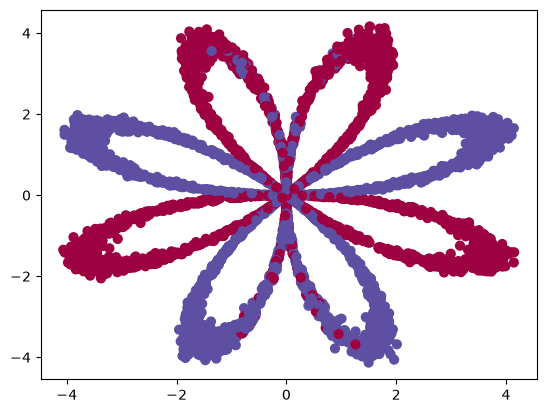

In [5]:
# Visualize the data:
plt.scatter(X[:,0], X[:,1], c=y.ravel(), s=40, cmap=plt.cm.Spectral)
## como podemos ver en esta imagen este problema no lo podremos resolver tan facilmente dibujando una linea para separa, por ello sera necesario hacerlo con otra forma de sesolucion

In [6]:
# train test split
from sklearn.model_selection import train_test_split

(X_train, X_test, y_train, y_test) = train_test_split(
    X,
    y,
    test_size=0.2,
)

In [7]:
print('X shape:{0}, y shape:{1}'.format(X.shape, y.shape))
print('X_train shape:{0}, y_train shape:{1}'.format(X_train.shape,
                                                    y_train.shape))
print('X_test shape:{0}, y_test shape:{1}'.format(X_test.shape, y_test.shape))

X shape:(5000, 2), y shape:(5000,)
X_train shape:(4000, 2), y_train shape:(4000,)
X_test shape:(1000, 2), y_test shape:(1000,)


In [8]:
## Y firsts examples
y[:8]

array([0, 0, 0, 1, 0, 0, 1, 1], dtype=uint8)

In [9]:
## X first example
X[0,:]

array([1.39178978, 2.13601744])

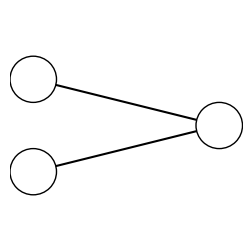

In [10]:
draw_neural_net(.1, .9, .1, .9, [2, 1]) # estos serian nuestros datos de entrada de ejemplo y como se puede ver solo tendria una capa de salida. nuestro problema al ser de clasificacion binaria, solo deberá de tener una salida tmb

In [11]:
model = keras.Sequential()
# The dimension of the input is 2 (planar data)
# we have only one output layer with 1 neuron
# Alternative: model.add(keras.Input(shape=(2,))) then model.add(Dense(1, activation='sigmoid'))
model.add(keras.layers.Dense(1, input_shape=(2, ), activation='sigmoid')) # se le van añadiendo las capas de esta forma (con el add). si queremos añadir mas, añadimos mas.

/home/jerry/anaconda3/lib/python3.14/site-packages/keras/src/layers/core/dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
E0000 00:00:1791704133.055005   14971 cuda_executor.cc:1690] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:68

W0000 00:00:1791704133.055372   15040 cuda_executor.cc:1710] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:77
external/xla/x

In [12]:
model.summary() # aqui podemos ver informacion basica de nuetro modelo. como podoemos ver solo tenemos 3 parametros

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3 (12.00 B)

 Trainable params: 3 (12.00 B)

 Non-trainable params: 0 (0.00 B)

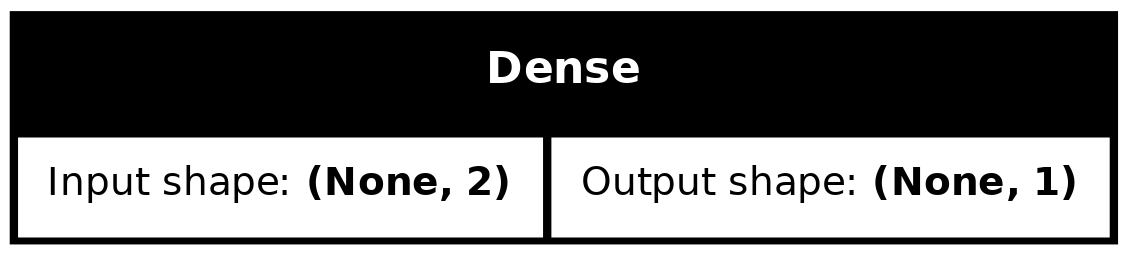

In [13]:
from tensorflow.keras.utils import plot_model
plot_model(model, show_shapes=True)

In [ ]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
) # lo dejamos predefinido pero lo vermeos mas adelante

In [ ]:
model.fit(X_train, y_train, epochs=10,
          validation_split=0.2, batch_size=32) # entrenamiento: nos pone lo que va haciendo en cada etapa. tanto el test como el validation. esto pone bastante pobre. vemos q es solo una resta

Epoch 1/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4528 - loss: 1.3121 - val_accuracy: 0.4462 - val_loss: 1.2588
Epoch 2/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4656 - loss: 1.2157 - val_accuracy: 0.4638 - val_loss: 1.1606
Epoch 3/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4794 - loss: 1.1256 - val_accuracy: 0.4712 - val_loss: 1.0702
Epoch 4/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4922 - loss: 1.0433 - val_accuracy: 0.4863 - val_loss: 0.9887
Epoch 5/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5056 - loss: 0.9695 - val_accuracy: 0.4975 - val_loss: 0.9170
Epoch 6/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5119 - loss: 0.9050 - val_accuracy: 0.5075 - val_loss: 0.8557
Epoch 7/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5144 - loss: 0.8502 - val_accuracy: 0.5275 - val_loss: 0.8046
Epoch 8/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5231 - loss: 0.8047 - val_accuracy: 0.

In [ ]:
results = model.evaluate(X_test, y_test, verbose=0)
print('Test Loss: {}'.format(results[0]))
print('Test Accuracy: {}'.format(results[1])) # el evaluate es para q nos de el loss y el accuracy de los datos de test

Test Loss: 0.7051478624343872
Test Accuracy: 0.6159999966621399


In [17]:
y_pred = model.predict(X_test)
y_pred[:3], y_test[:3]

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


(array([[0.46638313],
        [0.28929076],
        [0.37567103]], dtype=float32),
 array([1, 0, 0], dtype=uint8))

1307/1307 ━━━━━━━━━━━━━━━━━━━━ 1s 789us/step


Text(0.5, 1.0, 'Basic NN')

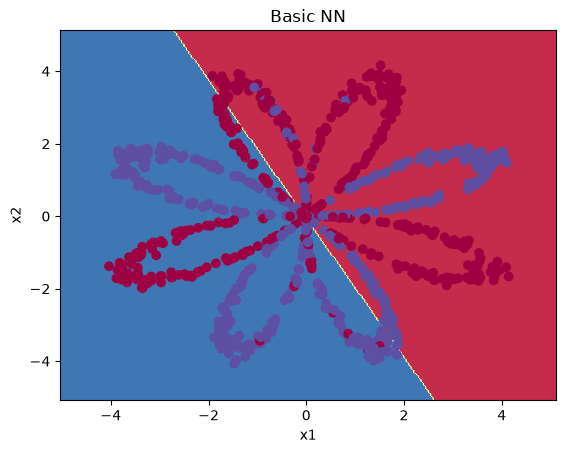

In [ ]:
plot_decision_boundary(lambda x: (
    model.predict(x) > 0.5).astype("int32"), X_test, y_test)
plt.title("Basic NN") # como podemos ver, aqui solo ha aprendido con una recta al ser un modelo sencillo. para resolverlo deberiamos de tener puesta una capa oculta para que sea mas eficiente este modelo

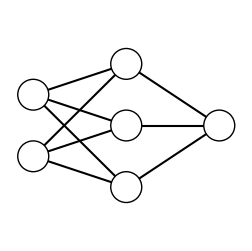

In [ ]:
draw_neural_net(.1, .9, .1, .9, [2, 3, 1]) # de esta forma tenemos puesta una capa oculta dentro de la red neuronal donde asi podemos hacer que sea un modelo mas eficiente y asi podra ser mas realista los resultados que va a adar nuestro modelo

In [ ]:
model = keras.Sequential()

## hidden layer with 3 neurons and sigmoid activation
## The first layer need to have the input_shape
model.add(layers.Dense(3, input_shape=(2,), activation='sigmoid')) # aqui añadimos la primera capa de 3 nodos
# output layer
model.add(layers.Dense(1, activation='sigmoid')) # añadimos la capa final de salida.

## model summary
model.summary()

/home/jerry/anaconda3/lib/python3.14/site-packages/keras/src/layers/core/dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 3)              │             9 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             4 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13 (52.00 B)

 Trainable params: 13 (52.00 B)

 Non-trainable params: 0 (0.00 B)

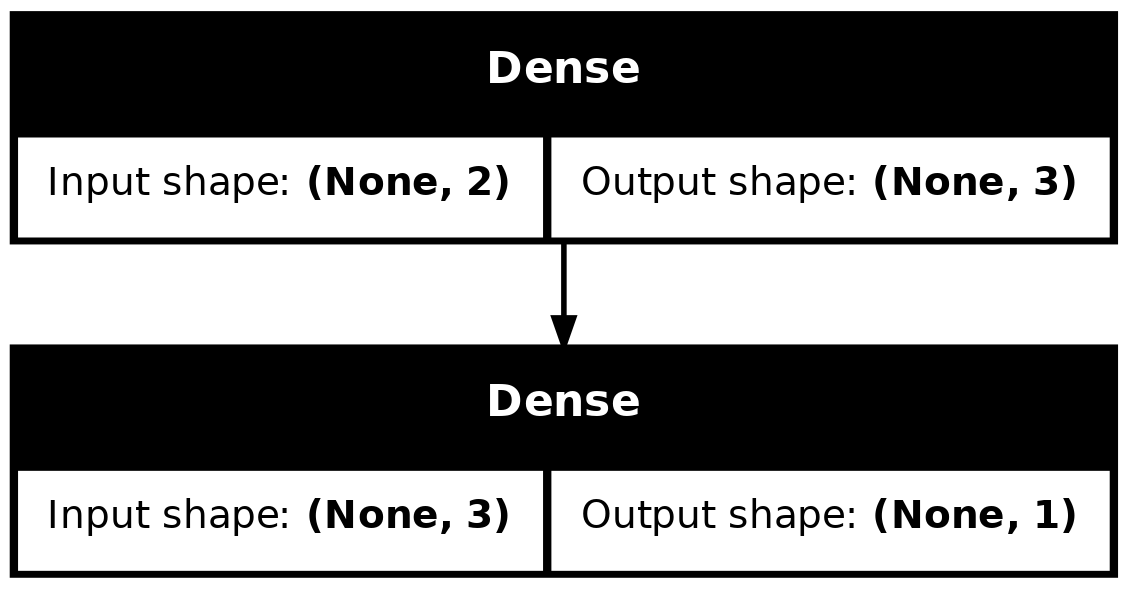

In [21]:
plot_model(model, show_shapes=True)

Epoch 1/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4487 - loss: 0.7386 - val_accuracy: 0.4725 - val_loss: 0.7276
Epoch 2/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4787 - loss: 0.7175 - val_accuracy: 0.4988 - val_loss: 0.7080
Epoch 3/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4950 - loss: 0.7023 - val_accuracy: 0.5175 - val_loss: 0.6935
Epoch 4/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5419 - loss: 0.6916 - val_accuracy: 0.5962 - val_loss: 0.6828
Epoch 5/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6250 - loss: 0.6841 - val_accuracy: 0.6888 - val_loss: 0.6749
Epoch 6/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6722 - loss: 0.6789 - val_accuracy: 0.6950 - val_loss: 0.6691
Epoch 7/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6634 - loss: 0.6752 - val_accuracy: 0.6687 - val_loss: 0.6647
Epoch 8/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6306 - loss: 0.6723 - val_accuracy: 0.

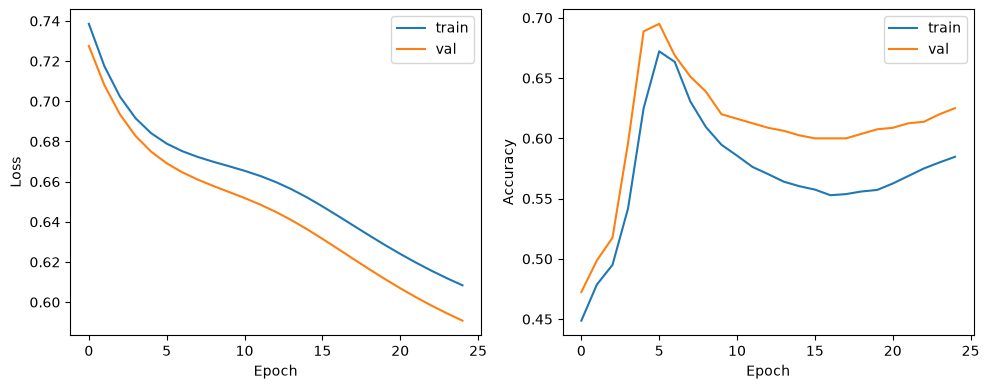

In [22]:
## compiling and training
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)
history = model.fit(X_train, y_train, epochs=25, validation_split=0.2, batch_size=32)
plot_history(history)

In [ ]:
results = model.evaluate(X_test, y_test, verbose=0)
print('Test Loss: {}'.format(results[0])) 
print('Test Accuracy: {}'.format(results[1])) # como vemos en los resultados no ha funcionado muy bien. porq el accuracy es bajo. es mejor q el anterior pero es muy pobre

Test Loss: 0.5931037068367004
Test Accuracy: 0.5960000157356262


1307/1307 ━━━━━━━━━━━━━━━━━━━━ 1s 744us/step


Text(0.5, 1.0, '1 Hidden layer NN')

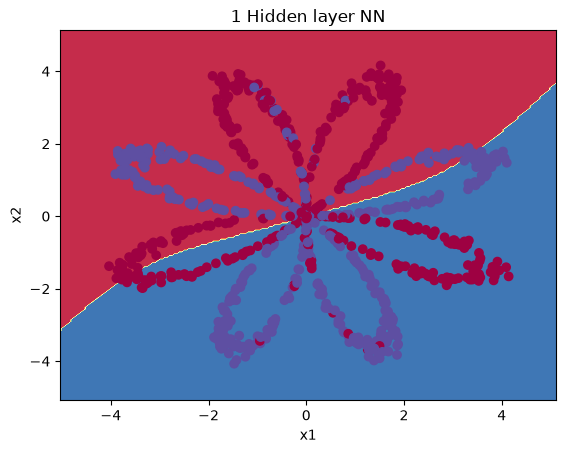

In [ ]:
plot_decision_boundary(lambda x: (
    model.predict(x) > 0.5).astype("int32"), X_test, y_test)
plt.title("1 Hidden layer NN") # al ser un poco mas complejo, vemos el plot. como se puede observar, ha aprendido una ligera curva. Igual hay que añadirle un poco mas de complejidad.

### ahora vamos a practicar por nuestra cuenta con algunas preguntas que nos pone para ver el modelo con toras caracterisitcas

In [25]:
model = keras.Sequential()
## The first layer need to have the input_shape
## change the activation function
model.add(layers.Dense(3, input_shape=(2,), activation='linear'))
# output layer
model.add(layers.Dense(1, activation='sigmoid'))

/home/jerry/anaconda3/lib/python3.14/site-packages/keras/src/layers/core/dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [26]:
## compiling and training
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)
model.fit(X_train, y_train, epochs=25, validation_split=0.2, batch_size=32)

Epoch 1/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5272 - loss: 0.6811 - val_accuracy: 0.5638 - val_loss: 0.6456
Epoch 2/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4959 - loss: 0.6660 - val_accuracy: 0.5300 - val_loss: 0.6439
Epoch 3/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4709 - loss: 0.6635 - val_accuracy: 0.5050 - val_loss: 0.6444
Epoch 4/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4578 - loss: 0.6631 - val_accuracy: 0.5075 - val_loss: 0.6448
Epoch 5/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4581 - loss: 0.6631 - val_accuracy: 0.5088 - val_loss: 0.6449
Epoch 6/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4584 - loss: 0.6631 - val_accuracy: 0.5088 - val_loss: 0.6449
Epoch 7/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4584 - loss: 0.6631 - val_accuracy: 0.5088 - val_loss: 0.6450
Epoch 8/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4584 - loss: 0.6631 - val_accuracy: 0.

Test Loss: 0.6487451791763306
Test Accuracy: 0.4869999885559082
1307/1307 ━━━━━━━━━━━━━━━━━━━━ 1s 613us/step


Text(0.5, 1.0, '1 Hidden layer NN, linear activation')

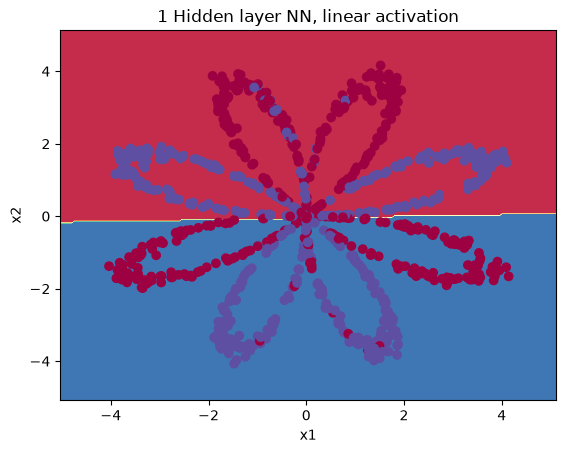

In [ ]:
results = model.evaluate(X_test, y_test, verbose=0)
print('Test Loss: {}'.format(results[0]))
print('Test Accuracy: {}'.format(results[1]))
plot_decision_boundary(lambda x: (
    model.predict(x) > 0.5).astype("int32"), X_test, y_test)
plt.title("1 Hidden layer NN, linear activation") # aqui con la primera capa como linear lo que ha hecho ha sido eliminar un poco la curva y incluso ha sido menos eficiente el modelo

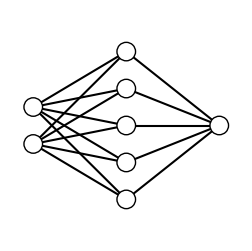

In [ ]:
## vamos a añadir mas nodos a la primera capa a ver que pasa y lo dejamos con sigmoid:
draw_neural_net(.1, .9, .1, .9, [2, 5, 1])

In [30]:
model = keras.Sequential()

## The first layer need to have the input_shape
## set the number of neurons
model.add(layers.Dense(5, input_shape=(2,), activation='sigmoid'))

# output layer
model.add(layers.Dense(1, activation='sigmoid'))

In [31]:
## compiling and training
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)
model.fit(X_train, y_train, epochs=25, validation_split=0.2, batch_size=32)

Epoch 1/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4884 - loss: 0.7458 - val_accuracy: 0.5063 - val_loss: 0.7079
Epoch 2/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5497 - loss: 0.6934 - val_accuracy: 0.5838 - val_loss: 0.6700
Epoch 3/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6237 - loss: 0.6681 - val_accuracy: 0.6800 - val_loss: 0.6511
Epoch 4/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6488 - loss: 0.6553 - val_accuracy: 0.6637 - val_loss: 0.6401
Epoch 5/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6350 - loss: 0.6474 - val_accuracy: 0.6600 - val_loss: 0.6324
Epoch 6/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6263 - loss: 0.6417 - val_accuracy: 0.6463 - val_loss: 0.6262
Epoch 7/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6166 - loss: 0.6370 - val_accuracy: 0.6363 - val_loss: 0.6211
Epoch 8/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6056 - loss: 0.6330 - val_accuracy: 0.

Test Loss: 0.5654144287109375
Test Accuracy: 0.5929999947547913
1307/1307 ━━━━━━━━━━━━━━━━━━━━ 1s 553us/step


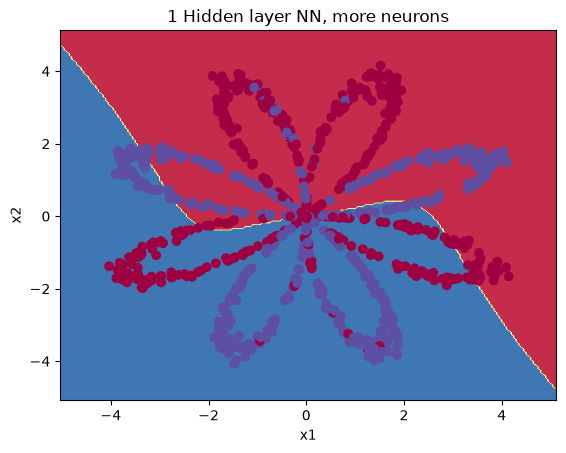

In [ ]:
results = model.evaluate(X_test, y_test, verbose=0)
print('Test Loss: {}'.format(results[0]))
print('Test Accuracy: {}'.format(results[1]))
plot_decision_boundary(lambda x: (
    model.predict(x) > 0.5).astype("int32"), X_test, y_test)
plt.title("1 Hidden layer NN, more neurons") # aqui como podemos ver parece que ha mejorado algo el modelo pero siue sin pillro bien. eso si parece que las curva las empieza a hacer bien pero a destiempo (yo creo que si ponemos otra capa oculta igual podría funcionar bastante mejor pero me espero). bueno es el siguiente ejercicio xd

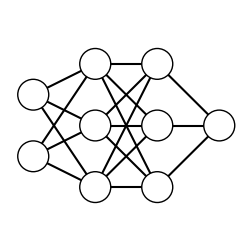

In [ ]:
draw_neural_net(.1, .9, .1, .9, [2, 3, 3, 1]) # añadimos una capa mas

In [34]:
model = keras.Sequential()
# First hidden layer (need to innclude input_shape)
## Set the number of neurons
model.add(layers.Dense(3, input_shape=(2,), activation='sigmoid'))

# second hidden layer
## Complete the code
model.add(layers.Dense(3, activation='sigmoid'))

# output layer
model.add(layers.Dense(1, activation='sigmoid'))

/home/jerry/anaconda3/lib/python3.14/site-packages/keras/src/layers/core/dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [35]:
## compiling and training
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)
model.fit(X_train, y_train, epochs=25, validation_split=0.2, batch_size=32)

Epoch 1/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4988 - loss: 0.7209 - val_accuracy: 0.4913 - val_loss: 0.7088
Epoch 2/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4988 - loss: 0.7003 - val_accuracy: 0.4913 - val_loss: 0.6953
Epoch 3/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4988 - loss: 0.6924 - val_accuracy: 0.4913 - val_loss: 0.6892
Epoch 4/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5516 - loss: 0.6884 - val_accuracy: 0.6212 - val_loss: 0.6851
Epoch 5/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5788 - loss: 0.6852 - val_accuracy: 0.5688 - val_loss: 0.6812
Epoch 6/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5431 - loss: 0.6819 - val_accuracy: 0.5825 - val_loss: 0.6772
Epoch 7/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5541 - loss: 0.6783 - val_accuracy: 0.6125 - val_loss: 0.6729
Epoch 8/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5691 - loss: 0.6745 - val_accuracy: 0.

Test Loss: 0.5842481851577759
Test Accuracy: 0.6309999823570251
1307/1307 ━━━━━━━━━━━━━━━━━━━━ 1s 619us/step


Text(0.5, 1.0, '2 Hidden layers NN')

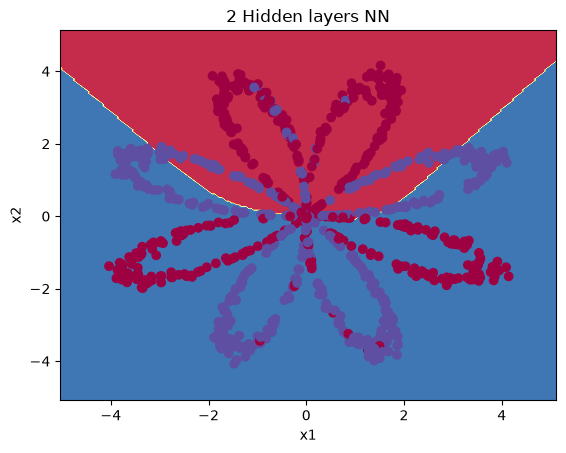

In [ ]:
results = model.evaluate(X_test, y_test, verbose=0)
print('Test Loss: {}'.format(results[0]))
print('Test Accuracy: {}'.format(results[1]))
plot_decision_boundary(lambda x: (
    model.predict(x) > 0.5).astype("int32"), X_test, y_test)
plt.title("2 Hidden layers NN") # parece que añadiendo una mas funciona mucho mejor. pero no sabemos tmpb hasta que puneto es mejor esto

In [37]:
model = keras.Sequential()
## The first layer need to have the input_shape
## change the activation function
model.add(layers.Dense(3, input_shape=(2,), activation='tanh')) # añadimos activacion tanh
# output layer
model.add(layers.Dense(1, activation='sigmoid'))

/home/jerry/anaconda3/lib/python3.14/site-packages/keras/src/layers/core/dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [38]:
## compiling and training
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)
model.fit(X_train, y_train, epochs=25, validation_split=0.2, batch_size=32)

Epoch 1/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5556 - loss: 0.6520 - val_accuracy: 0.5962 - val_loss: 0.6271
Epoch 2/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5509 - loss: 0.6361 - val_accuracy: 0.5925 - val_loss: 0.6147
Epoch 3/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5531 - loss: 0.6255 - val_accuracy: 0.5987 - val_loss: 0.6060
Epoch 4/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5622 - loss: 0.6178 - val_accuracy: 0.6037 - val_loss: 0.5989
Epoch 5/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5706 - loss: 0.6116 - val_accuracy: 0.6175 - val_loss: 0.5926
Epoch 6/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5816 - loss: 0.6062 - val_accuracy: 0.6263 - val_loss: 0.5868
Epoch 7/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5922 - loss: 0.6013 - val_accuracy: 0.6313 - val_loss: 0.5814
Epoch 8/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5991 - loss: 0.5967 - val_accuracy: 0.

Test Loss: 0.5479934811592102
Test Accuracy: 0.5830000042915344
1307/1307 ━━━━━━━━━━━━━━━━━━━━ 1s 756us/step


Text(0.5, 1.0, '1 Hidden layer NN, tanh activation')

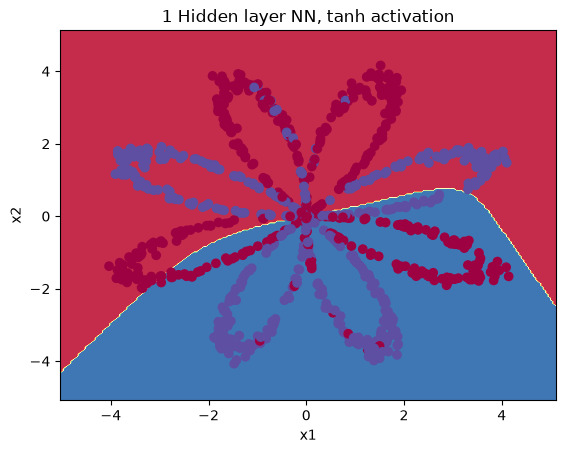

In [ ]:
results = model.evaluate(X_test, y_test, verbose=0)
print('Test Loss: {}'.format(results[0]))
print('Test Accuracy: {}'.format(results[1]))
plot_decision_boundary(lambda x: (
    model.predict(x) > 0.5).astype("int32"), X_test, y_test)
plt.title("1 Hidden layer NN, tanh activation") 

# Como practica. usar otro datset

In [40]:
N = 5000
X, y = sklearn.datasets.make_moons(n_samples=N, noise=.18)

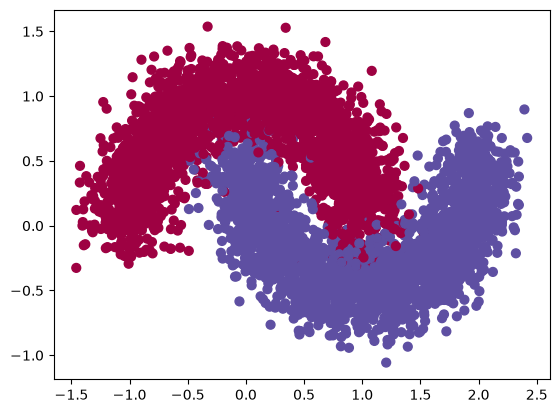

In [41]:
# Visualize the data:
plt.scatter(X[:,0], X[:,1], c=y.ravel(), s=40, cmap=plt.cm.Spectral);

In [42]:
# train test split
from sklearn.model_selection import train_test_split

(X_train, X_test, y_train, y_test) = train_test_split(
    X,
    y,
    test_size=0.25,
)
print('X shape:{0}, y shape:{1}'.format(X.shape, y.shape))
print('X_train shape:{0}, y_train shape:{1}'.format(X_train.shape,
                                                    y_train.shape))
print('X_test shape:{0}, y_test shape:{1}'.format(X_test.shape, y_test.shape))

X shape:(5000, 2), y shape:(5000,)
X_train shape:(3750, 2), y_train shape:(3750,)
X_test shape:(1250, 2), y_test shape:(1250,)


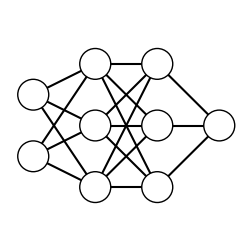

In [43]:
draw_neural_net(.1, .9, .1, .9, [2, 3, 3, 1]) # uso esta forma para probar el modelo

In [44]:
model = keras.Sequential()
# First hidden layer (need to innclude input_shape)
## Set the number of neurons
model.add(layers.Dense(3, input_shape=(2,), activation='sigmoid'))

# second hidden layer
## Complete the code
model.add(layers.Dense(3, activation='sigmoid'))

# output layer
model.add(layers.Dense(1, activation='sigmoid'))## voy a usar lonq  mejor me ha funcionado en el ejemplo anterior aunque no tiene q ser asi

In [45]:
## compiling and training
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)
model.fit(X_train, y_train, epochs=35, validation_split=0.2, batch_size=64)

Epoch 1/35
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.4967 - loss: 0.7162 - val_accuracy: 0.5053 - val_loss: 0.7058
Epoch 2/35
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4967 - loss: 0.7022 - val_accuracy: 0.5053 - val_loss: 0.6948
Epoch 3/35
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4967 - loss: 0.6919 - val_accuracy: 0.5053 - val_loss: 0.6862
Epoch 4/35
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4967 - loss: 0.6835 - val_accuracy: 0.5053 - val_loss: 0.6784
Epoch 5/35
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5443 - loss: 0.6754 - val_accuracy: 0.7360 - val_loss: 0.6702
Epoch 6/35
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7857 - loss: 0.6668 - val_accuracy: 0.8093 - val_loss: 0.6611
Epoch 7/35
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8050 - loss: 0.6573 - val_accuracy: 0.8360 - val_loss: 0.6508
Epoch 8/35
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8040 - loss: 0.6468 - val_accuracy: 0.8333 - val_loss

Test Loss: 0.3562029302120209
Test Accuracy: 0.8543999791145325
318/318 ━━━━━━━━━━━━━━━━━━━━ 0s 728us/step


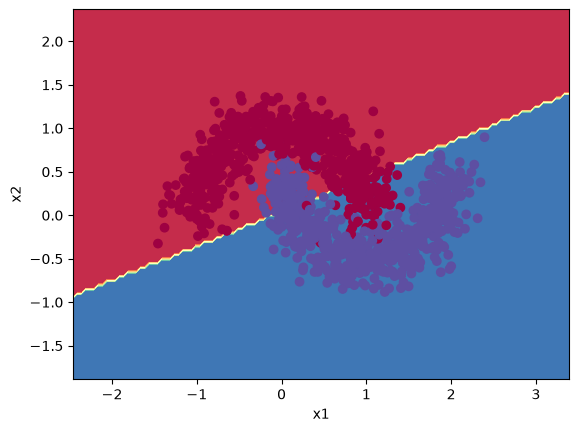

In [ ]:
results = model.evaluate(X_test, y_test, verbose=0)
print('Test Loss: {}'.format(results[0]))
print('Test Accuracy: {}'.format(results[1]))
plot_decision_boundary(lambda x: (
    model.predict(x) > 0.5).astype("int32"), X_test, y_test) # aprece nastante bueno la linea que ha egnerado pero vamos a probar con otra activacion distina y una capa menos para ver si va mejor

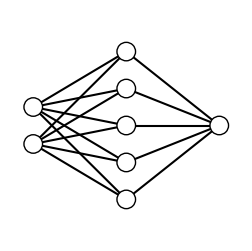

In [47]:
draw_neural_net(.1, .9, .1, .9, [2, 5, 1]) # uso esta forma para probar el modelo

In [48]:
model = keras.Sequential()
# First hidden layer (need to innclude input_shape)
## Set the number of neurons
model.add(layers.Dense(5, input_shape=(2,), activation='tanh'))


# output layer
model.add(layers.Dense(1, activation='sigmoid'))

/home/jerry/anaconda3/lib/python3.14/site-packages/keras/src/layers/core/dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [49]:
## compiling and training
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)
model.fit(X_train, y_train, epochs=35, validation_split=0.2, batch_size=64)

Epoch 1/35
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.7570 - loss: 0.5858 - val_accuracy: 0.7907 - val_loss: 0.5647
Epoch 2/35
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7803 - loss: 0.5476 - val_accuracy: 0.8013 - val_loss: 0.5276
Epoch 3/35
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7950 - loss: 0.5139 - val_accuracy: 0.8120 - val_loss: 0.4945
Epoch 4/35
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8033 - loss: 0.4841 - val_accuracy: 0.8240 - val_loss: 0.4648
Epoch 5/35
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8080 - loss: 0.4579 - val_accuracy: 0.8307 - val_loss: 0.4385
Epoch 6/35
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8123 - loss: 0.4353 - val_accuracy: 0.8360 - val_loss: 0.4156
Epoch 7/35
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8177 - loss: 0.4159 - val_accuracy: 0.8413 - val_loss: 0.3956
Epoch 8/35
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8227 - loss: 0.3992 - val_accuracy: 0.8493 - val_loss

Test Loss: 0.2949802577495575
Test Accuracy: 0.8615999817848206
318/318 ━━━━━━━━━━━━━━━━━━━━ 0s 620us/step


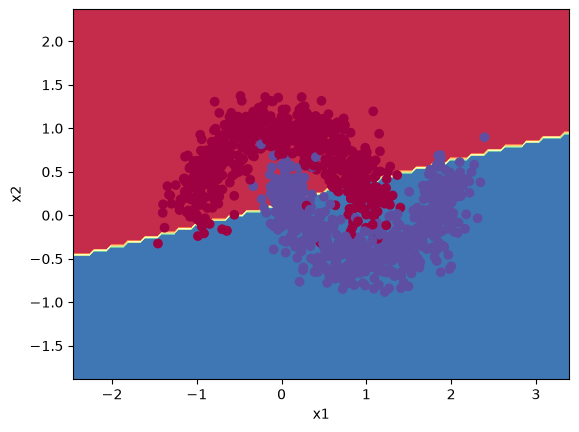

In [ ]:
results = model.evaluate(X_test, y_test, verbose=0)
print('Test Loss: {}'.format(results[0]))
print('Test Accuracy: {}'.format(results[1]))
plot_decision_boundary(lambda x: (
    model.predict(x) > 0.5).astype("int32"), X_test, y_test) # parace que funciona igual con una capa que con 2, es bastante parecedo el modelo. por lo tanto vamos a hacerlo aun mas simple

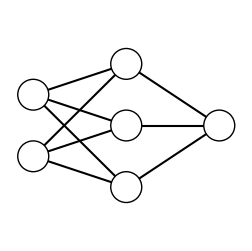

In [51]:
draw_neural_net(.1, .9, .1, .9, [2, 3, 1]) # uso esta forma para probar el modelo

In [52]:
model = keras.Sequential()
# First hidden layer (need to innclude input_shape)
## Set the number of neurons
model.add(layers.Dense(3, input_shape=(2,), activation='tanh'))


# output layer
model.add(layers.Dense(1, activation='sigmoid'))

/home/jerry/anaconda3/lib/python3.14/site-packages/keras/src/layers/core/dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [53]:
## compiling and training
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)
model.fit(X_train, y_train, epochs=35, validation_split=0.2, batch_size=64)

Epoch 1/35
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.5707 - loss: 0.6835 - val_accuracy: 0.6027 - val_loss: 0.6575
Epoch 2/35
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6507 - loss: 0.6287 - val_accuracy: 0.6680 - val_loss: 0.6063
Epoch 3/35
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6943 - loss: 0.5833 - val_accuracy: 0.7160 - val_loss: 0.5640
Epoch 4/35
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7253 - loss: 0.5461 - val_accuracy: 0.7400 - val_loss: 0.5291
Epoch 5/35
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7393 - loss: 0.5157 - val_accuracy: 0.7573 - val_loss: 0.5001
Epoch 6/35
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7540 - loss: 0.4907 - val_accuracy: 0.7667 - val_loss: 0.4756
Epoch 7/35
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7633 - loss: 0.4697 - val_accuracy: 0.7773 - val_loss: 0.4547
Epoch 8/35
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7767 - loss: 0.4519 - val_accuracy: 0.7907 - val_loss

Test Loss: 0.2955475449562073
Test Accuracy: 0.8615999817848206
318/318 ━━━━━━━━━━━━━━━━━━━━ 0s 660us/step


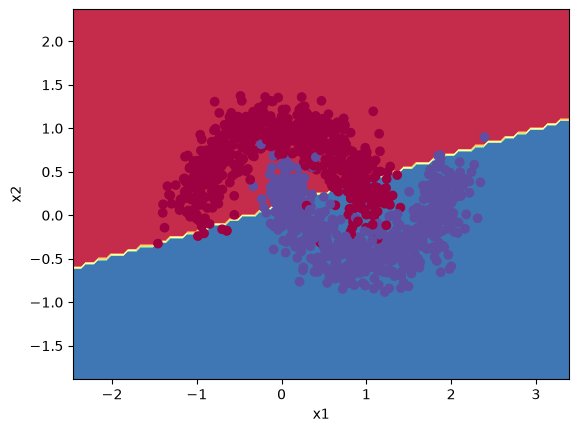

In [ ]:
results = model.evaluate(X_test, y_test, verbose=0)
print('Test Loss: {}'.format(results[0]))
print('Test Accuracy: {}'.format(results[1]))
plot_decision_boundary(lambda x: (
    model.predict(x) > 0.5).astype("int32"), X_test, y_test) # parace que funciona bastante bien tambien por lo tanto igual no deberiamos de tocarlo msa

## ahroa vamos a ver la functional api de jkeras

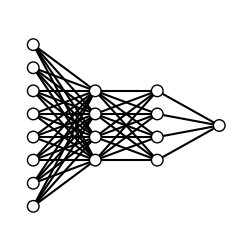

In [55]:
draw_neural_net(.1, .9, .1, .9, [8, 4, 4, 1])

In [56]:
inputs = keras.Input(shape=(8, ), name='input_layer')
l_1 = layers.Dense(4, activation='relu', name='layer_1')(inputs)
l_2 = layers.Dense(4, activation='relu', name='layer_2')(l_1)
outputs = layers.Dense(1, activation="sigmoid", name='output_layer')(l_2)

model = keras.Model(inputs=inputs, outputs=outputs, name='example_model')

model.summary()

Model: "example_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_1 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_2 (Dense)                 │ (None, 4)              │            20 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 61 (244.00 B)

 Trainable params: 61 (244.00 B)

 Non-trainable params: 0 (0.00 B)

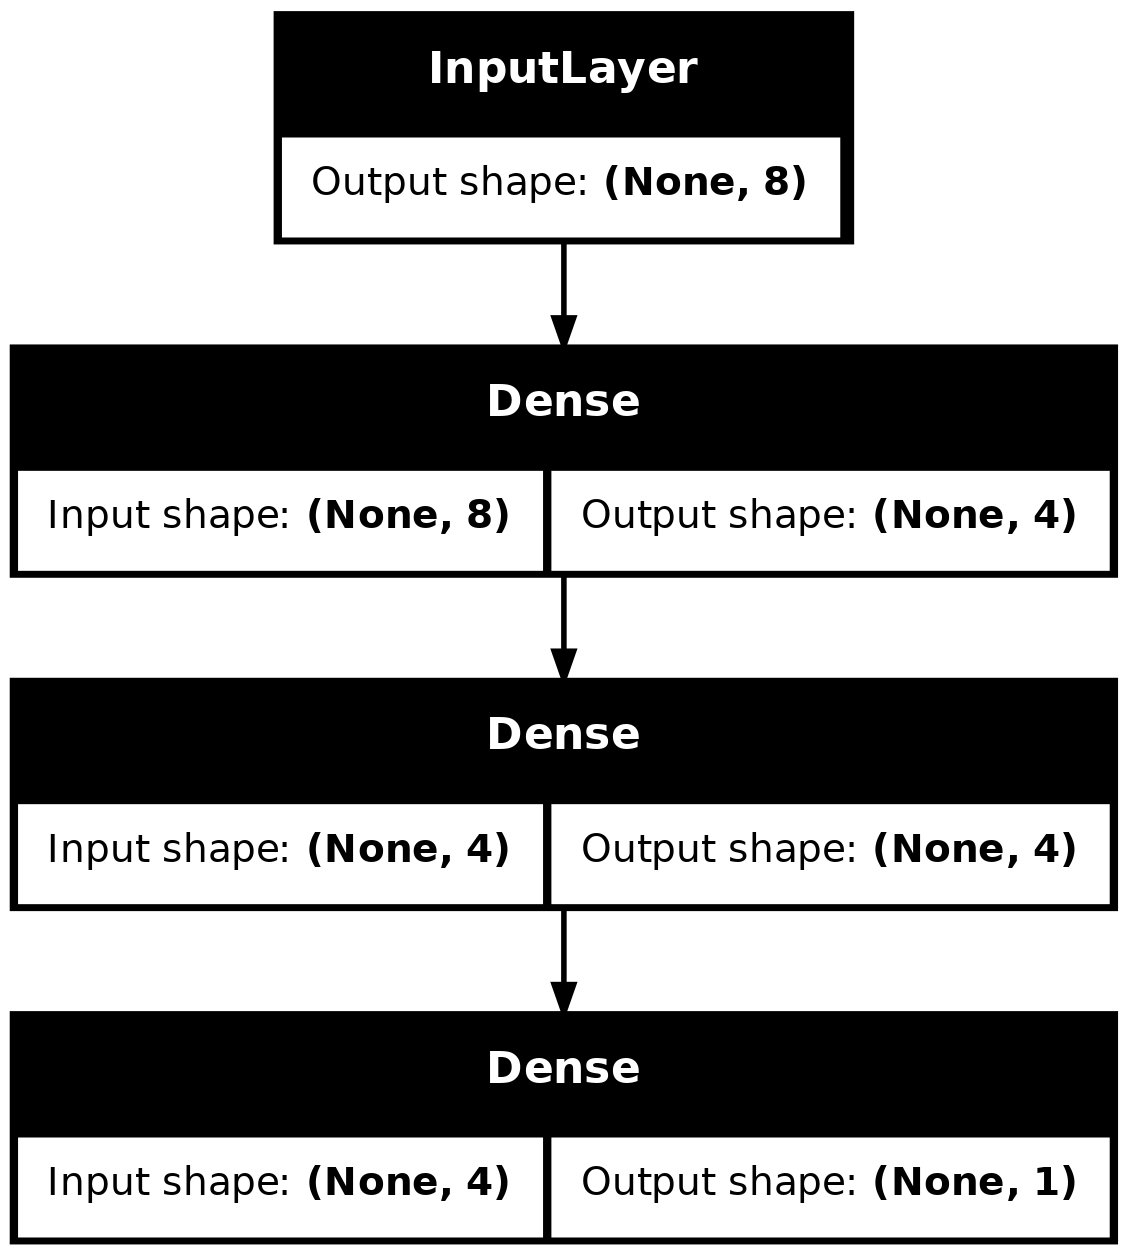

In [57]:
plot_model(model, show_shapes=True)

# vamos ahora a ver con otro dataser

In [58]:
N = 5000
X, y = sklearn.datasets.make_circles(n_samples=N, factor=.65, noise=.065) # sklearn.datasets.make_moons(n_samples=N, noise=.15)

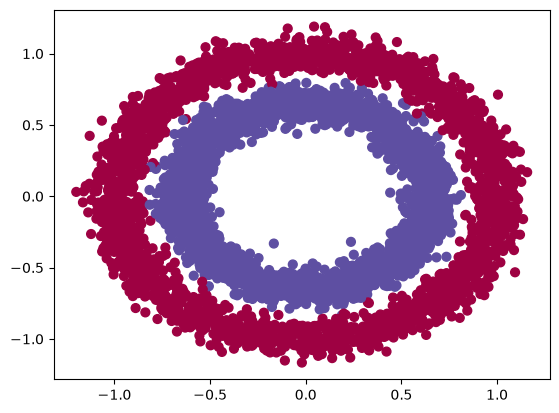

In [59]:
# Visualize the data:
plt.scatter(X[:,0], X[:,1], c=y.ravel(), s=40, cmap=plt.cm.Spectral);

In [60]:
# train test split
from sklearn.model_selection import train_test_split

(X_train, X_test, y_train, y_test) = train_test_split(
    X,
    y,
    test_size=0.25,
)
print('X shape:{0}, y shape:{1}'.format(X.shape, y.shape))
print('X_train shape:{0}, y_train shape:{1}'.format(X_train.shape,
                                                    y_train.shape))
print('X_test shape:{0}, y_test shape:{1}'.format(X_test.shape, y_test.shape))

X shape:(5000, 2), y shape:(5000,)
X_train shape:(3750, 2), y_train shape:(3750,)
X_test shape:(1250, 2), y_test shape:(1250,)


In [62]:
inputs = keras.Input(shape=(2, ), name='input_layer')
## First hidden layer
l_1 = layers.Dense(8, activation='tanh')(inputs)
#second hidden layer
l_2 = layers.Dense(8, activation='tanh')(l_1) # aqui de esta forma como se esta haciendo con keras funciona distinto. como podemos ver se tiene que crear previament ela variable inputas y luego poner entre parentesis despues la capa de entrada anterior. es decir. la primer capa tiene como entrada los inputs mientras que la segunda capa tiene como entrada la primera capa

## output layer
outputs = layers.Dense(1,activation='sigmoid')(l_2) # al ser clasificacion binaria, tiene que ser la ultima capa una sigmoid

                       

model = keras.Model(inputs=inputs,outputs=outputs)

In [63]:
## compiling and training
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)
model.fit(X_train, y_train, epochs=35, validation_split=0.2, batch_size=64)

Epoch 1/35
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.5130 - loss: 0.7056 - val_accuracy: 0.5173 - val_loss: 0.6973
Epoch 2/35
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5507 - loss: 0.6916 - val_accuracy: 0.5413 - val_loss: 0.6902
Epoch 3/35
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5460 - loss: 0.6896 - val_accuracy: 0.5133 - val_loss: 0.6880
Epoch 4/35
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5317 - loss: 0.6880 - val_accuracy: 0.5107 - val_loss: 0.6862
Epoch 5/35
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5330 - loss: 0.6862 - val_accuracy: 0.5107 - val_loss: 0.6841
Epoch 6/35
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5390 - loss: 0.6840 - val_accuracy: 0.5107 - val_loss: 0.6816
Epoch 7/35
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5473 - loss: 0.6813 - val_accuracy: 0.5120 - val_loss: 0.6785
Epoch 8/35
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5617 - loss: 0.6781 - val_accuracy: 0.5187 - val_loss

Test Loss: 0.2534736394882202
Test Accuracy: 0.9887999892234802
229/229 ━━━━━━━━━━━━━━━━━━━━ 0s 852us/step


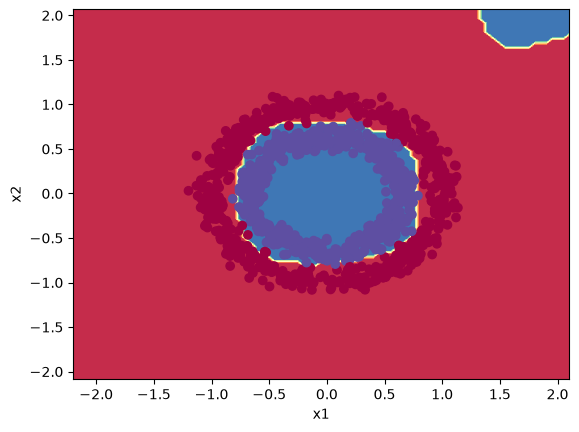

In [ ]:
results = model.evaluate(X_test, y_test, verbose=0)
print('Test Loss: {}'.format(results[0]))
print('Test Accuracy: {}'.format(results[1]))
plot_decision_boundary(lambda x: (
    model.predict(x) > 0.5).astype("int32"), X_test, y_test) # podemos ver que tenemos un modelo casi perfecto